# Random model

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import medmnist
import numpy as np
import os
import matplotlib.pyplot as plt
import sklearn.metrics as skmetrics
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision import models
from medmnist import INFO, Evaluator
from tqdm import tqdm
import random
from sklearn.metrics import roc_curve, auc as metrics_auc, f1_score, accuracy_score, hamming_loss, balanced_accuracy_score, confusion_matrix

Cargando los mejores pesos del modelo guardados por Early Stopping...


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:10<00:00, 16.29it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.0500
cardiomegaly    -> 0.0500
effusion        -> 0.0500
infiltration    -> 0.0500
mass            -> 0.0500
nodule          -> 0.0500
pneumonia       -> 0.0500
pneumothorax    -> 0.0500
consolidation   -> 0.0500
edema           -> 0.0500
emphysema       -> 0.0500
fibrosis        -> 0.0500
pleural         -> 0.0500
hernia          -> 0.0500


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:21<00:00, 16.64it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.5036
- Hamming Score (Acc)  : 0.0526
- Mean Balanced Acc    : 0.5000
- F1-Score Macro       : 0.0962
- F1-Score Micro       : 0.0999
- Accuracy Global (EMR): 0.0000


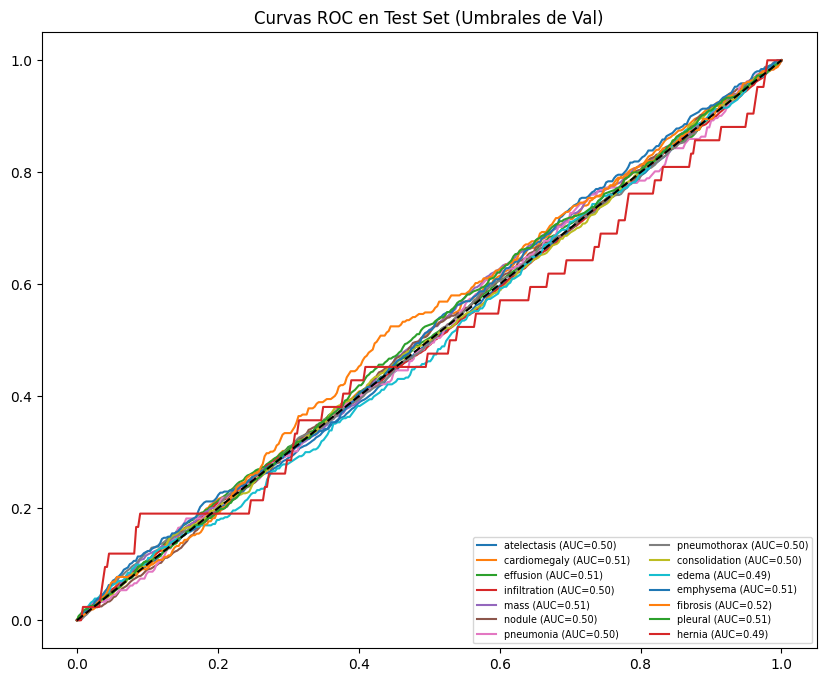

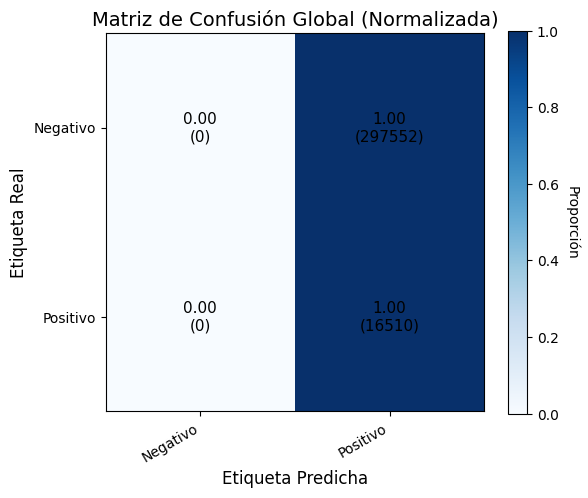

In [4]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
random.seed(42)
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_da_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
criterion = nn.BCEWithLogitsLoss()
#######################################################################

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = random.random() * torch.ones_like(targets)  # Que devuelva 0 o 1 aleatoriamente

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")



# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = random.random() * torch.ones_like(targets)  # Que devuelva 0 o 1 aleatoriamente
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()



# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()

## MODELO a 0 siempre

Cargando los mejores pesos del modelo guardados por Early Stopping...


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:10<00:00, 16.73it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.0500
cardiomegaly    -> 0.0500
effusion        -> 0.0500
infiltration    -> 0.0500
mass            -> 0.0500
nodule          -> 0.0500
pneumonia       -> 0.0500
pneumothorax    -> 0.0500
consolidation   -> 0.0500
edema           -> 0.0500
emphysema       -> 0.0500
fibrosis        -> 0.0500
pleural         -> 0.0500
hernia          -> 0.0500


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:21<00:00, 16.32it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.5000
- Hamming Score (Acc)  : 0.0526
- Mean Balanced Acc    : 0.5000
- F1-Score Macro       : 0.0962
- F1-Score Micro       : 0.0999
- Accuracy Global (EMR): 0.0000


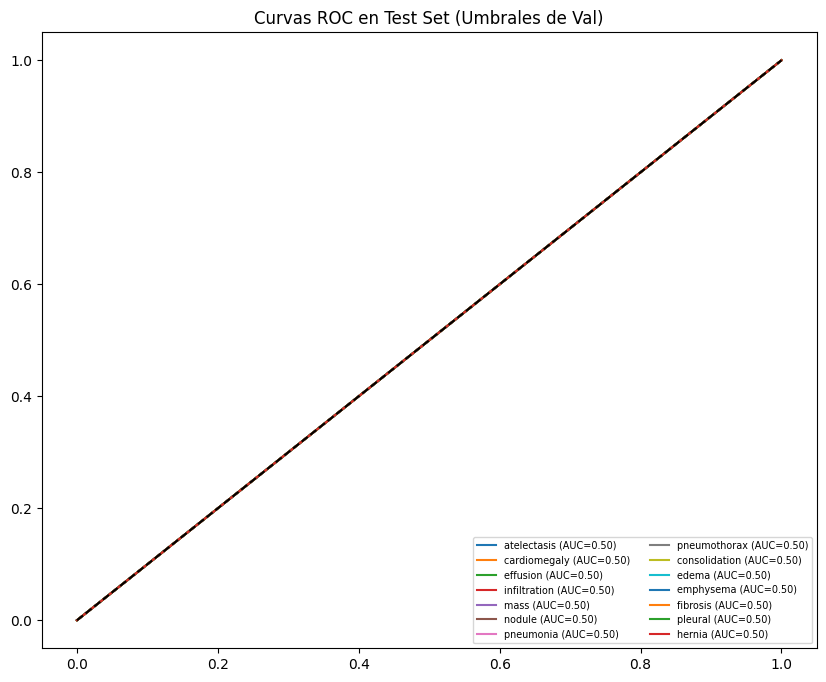

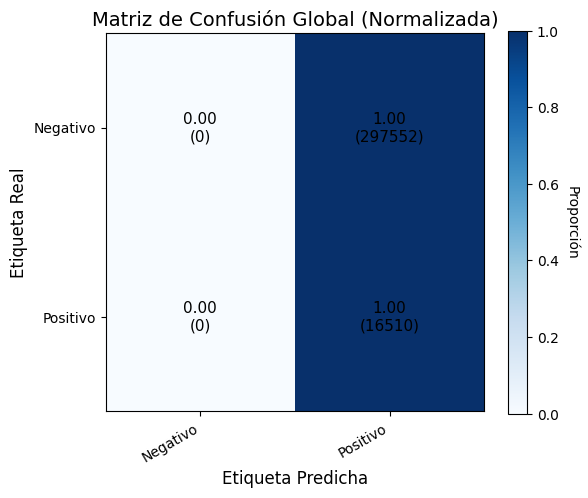

In [5]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
random.seed(42)
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_da_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
criterion = nn.BCEWithLogitsLoss()
#######################################################################

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = torch.zeros_like(targets)  # Que devuelva 0 siempre

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")



# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = torch.zeros_like(targets)  # Que devuelva 0 siempre
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()


# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()

## MODELO a 1 siempre

Cargando los mejores pesos del modelo guardados por Early Stopping...


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:11<00:00, 14.93it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.0500
cardiomegaly    -> 0.0500
effusion        -> 0.0500
infiltration    -> 0.0500
mass            -> 0.0500
nodule          -> 0.0500
pneumonia       -> 0.0500
pneumothorax    -> 0.0500
consolidation   -> 0.0500
edema           -> 0.0500
emphysema       -> 0.0500
fibrosis        -> 0.0500
pleural         -> 0.0500
hernia          -> 0.0500


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:22<00:00, 15.49it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.5000
- Hamming Score (Acc)  : 0.0526
- Mean Balanced Acc    : 0.5000
- F1-Score Macro       : 0.0962
- F1-Score Micro       : 0.0999
- Accuracy Global (EMR): 0.0000


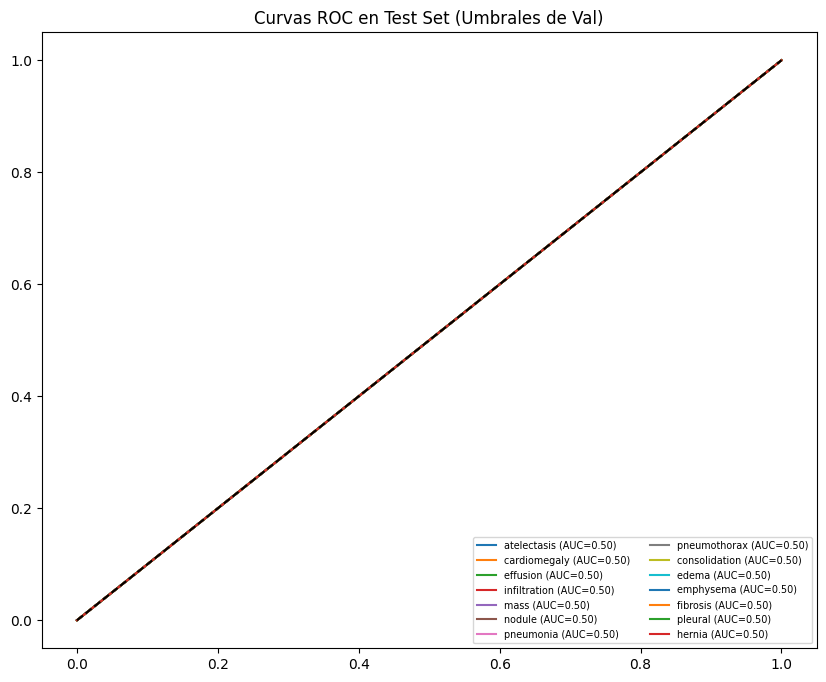

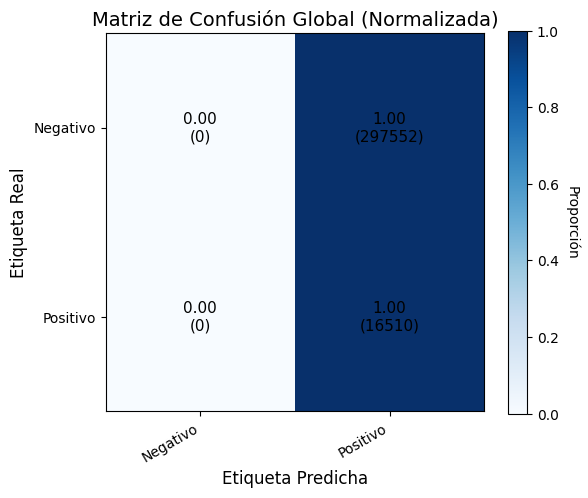

In [6]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
random.seed(42)
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_da_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
criterion = nn.BCEWithLogitsLoss()
#######################################################################

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = torch.ones_like(targets)  # Que devuelva 1 siempre

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")



# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = torch.ones_like(targets)  # Que devuelva 1 siempre
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()

# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()